In [40]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
import os

old_path = "/content/drive"
backup_path = "/content/drive_stale"

# Rename the old directory instead of deleting it
if os.path.exists(old_path) and not os.path.ismount(old_path):
    if not os.path.exists(backup_path):
        os.rename(old_path, backup_path)

# Create a fresh empty mount point
os.makedirs(old_path, exist_ok=True)

print("Fresh mount point created:", old_path)
print("Old files preserved at:", backup_path)
print("Current /content/drive contents:", os.listdir(old_path))

Fresh mount point created: /content/drive
Old files preserved at: /content/drive_stale
Current /content/drive contents: []


In [5]:
import os
from google.colab import drive

# Mount Google Drive to /content/drive
try:
    print("Mounting Google Drive...")
    drive.mount('/content/drive')
except Exception as e:
    print("Could not mount Google Drive automatically.", e)

# Check if the mount point and MyDrive directory now exist
if os.path.exists("/content/drive/MyDrive"):
    print("\nMy Drive contents:")
    print(os.listdir("/content/drive/MyDrive"))

    print("\nProject folder exists:")
    print(os.path.exists("/content/drive/MyDrive/Fruit_Classification_project"))

    print("\nTrain CSV exists:")
    print(os.path.exists(
        "/content/drive/MyDrive/Fruit_Classification_project/splits/train.csv"
    ))
else:
    print("\n[ERROR] /content/drive/MyDrive is still not accessible. Please ensure you authorize Google Drive access.")

Mounting Google Drive...
Mounted at /content/drive

My Drive contents:
['CoviD 19 chitra.pdf', 'S.Chithra .pdf', 'Profile - Public Distribution System.pdf', 'Vijay Reddy Files ', 'Vr photo ', "St.joseph's collage of Engineering documents ", 'Cerificate ', 'IMG-20241023-WA0004.jpg', '41471- A.jpg', 'Nptel', 'School certificate ', 'Document from VIJAY.PDF', '195 Vellaraia Old A Reg.pdf', 'Hackathon.pdf', 'Classroom', 'NPTEL.xlsx', 'Gmail - Welcome to NPTEL Online Course _ Demystifying Networking (1).PDF', 'Gmail - Welcome to NPTEL Online Course _ Demystifying Networking.PDF', 'Day Scholar Details.xlsx', 'round 1 result.xlsx', 'id card png.pdf', 'Document 32_1.jpg', 'Vijay Reddy_AIML_Certificate.pdf', 'VijayReddy Resume.pdf', 'Phantom coders sprintathon.pdf', 'voter recipt 2025.pdf', 'palur jana details full .pdf', 'chitra family details .pdf', 'Document 10_1.jpg', 'Big bucks offer letter internship (1).pdf', 'Big bucks offer letter internship.pdf', 'laptop order booked recepit .pdf', 'Co

In [6]:
# Dataset class with oversampling and augmentation
# Wait time is included to avoid Google Drive file access limit

import os
import time
import torch
from torch.utils.data import Dataset
from PIL import Image
from collections import Counter


class FruitClassificationDataset(Dataset):

    def __init__(self, main_dir, transform=None, balance=None):

        self.main_dir = main_dir
        self.transform = transform
        self.balance = balance

        self.classes = sorted(os.listdir(main_dir))

        self.quality_types = [
            'Good_Quality',
            'Bad_Quality',
            'Mixed_Quality'
        ]

        self.class_to_idx = {
            cls: idx for idx, cls in enumerate(self.classes)
        }

        self.all_imgs = [
            os.path.join(dp, f)
            for dp, dn, fn in os.walk(
                os.path.expanduser(main_dir)
            )
            for f in fn
            if f.endswith('.jpg') or f.endswith('.png')
        ]

        self.imgs_labelled = [
            (
                img,
                self.class_to_idx[
                    os.path.basename(
                        os.path.dirname(
                            os.path.dirname(img)
                        )
                    )
                ]
            )
            for img in self.all_imgs
        ]

        self.class_counts = Counter(
            img[1] for img in self.imgs_labelled
        )

        self.max_class_count = max(
            self.class_counts.values()
        )

        # Pre-calculate the list of samples for each class
        self.samples_by_class = [
            [
                img
                for img in self.imgs_labelled
                if img[1] == i
            ]
            for i in range(len(self.classes))
        ]

    def __len__(self):

        return len(self.classes) * self.max_class_count

    def wait_for_file(
        self,
        file_path,
        max_wait_time=120,
        delay=5
    ):

        total_wait_time = 0

        while total_wait_time < max_wait_time:

            if os.path.isfile(file_path):
                return True

            else:
                time.sleep(delay)
                total_wait_time += delay

        return False

    def __getitem__(self, index):

        class_index = index % len(self.classes)

        img_index = index // len(self.classes)

        class_samples = self.samples_by_class[class_index]

        img_index = img_index % len(class_samples)

        img_name, label = class_samples[img_index]

        # Wait for the image file to be accessible
        if not self.wait_for_file(img_name):
            raise FileNotFoundError(
                f"File not found after waiting: {img_name}"
            )

        # Load image
        image = Image.open(img_name).convert("RGB")

        # Apply oversampling augmentation
        if (
            self.balance
            and len(class_samples) < self.max_class_count
        ):
            image = self.balance(image)

        # Apply normal transformation
        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
# Dataset class with no oversampling and no augmentations

import os
import time
import torch
from torch.utils.data import Dataset
from PIL import Image


class ValTestFruitClassificationDataset(Dataset):

    def __init__(self, main_dir, preprocess=None):

        self.main_dir = main_dir
        self.preprocess = preprocess

        self.classes = sorted(os.listdir(main_dir))

        self.quality_types = [
            'Good_Quality',
            'Bad_Quality',
            'Mixed_Quality'
        ]

        self.class_to_idx = {
            cls: idx for idx, cls in enumerate(self.classes)
        }

        self.all_imgs = [
            os.path.join(dp, f)
            for dp, dn, fn in os.walk(
                os.path.expanduser(main_dir)
            )
            for f in fn
            if f.endswith('.jpg') or f.endswith('.png')
        ]

        self.imgs_labelled = [
            (
                img,
                self.class_to_idx[
                    os.path.basename(
                        os.path.dirname(
                            os.path.dirname(img)
                        )
                    )
                ]
            )
            for img in self.all_imgs
        ]

    def __len__(self):

        return len(self.imgs_labelled)

    def wait_for_file(
        self,
        file_path,
        max_wait_time=120,
        delay=5
    ):

        total_wait_time = 0

        while total_wait_time < max_wait_time:

            if os.path.isfile(file_path):
                return True

            else:
                time.sleep(delay)
                total_wait_time += delay

        # If the file isn't found within the max wait time
        return False

    def __getitem__(self, index):

        img_name, label = self.imgs_labelled[index]

        # Wait for the image file to be accessible
        if not self.wait_for_file(img_name):
            raise FileNotFoundError(
                f"File not found after waiting: {img_name}"
            )

        # Load image
        image = Image.open(img_name).convert("RGB")

        # Apply preprocessing only
        if self.preprocess:
            image = self.preprocess(image)

        return image, label

In [8]:
# Dataset class with oversampling and augmentation

import os
import time
from collections import Counter
from torch.utils.data import Dataset
from PIL import Image


class QualityClassificationDataset(Dataset):

    def __init__(self, main_dir, transform=None, balance=None):

        self.main_dir = main_dir
        self.transform = transform
        self.balance = balance

        self.quality_types = sorted([
            'Good_Quality',
            'Bad_Quality',
            'Mixed_Quality'
        ])

        self.quality_to_idx = {
            q: idx for idx, q in enumerate(self.quality_types)
        }

        self.all_imgs = [
            os.path.join(dp, f)
            for dp, dn, fn in os.walk(
                os.path.expanduser(main_dir)
            )
            for f in fn
            if f.endswith('.jpg') or f.endswith('.png')
        ]

        self.imgs_labelled = [
            (
                img,
                self.quality_to_idx[
                    os.path.basename(
                        os.path.dirname(img)
                    )
                ]
            )
            for img in self.all_imgs
        ]

        self.quality_counts = Counter(
            img[1] for img in self.imgs_labelled
        )

        self.max_quality_count = max(
            self.quality_counts.values()
        )

        # Pre-calculate the list of samples for each quality
        self.samples_by_quality = [
            [
                img
                for img in self.imgs_labelled
                if img[1] == i
            ]
            for i in range(len(self.quality_types))
        ]

    def __len__(self):

        return len(self.quality_types) * self.max_quality_count

    def wait_for_file(
        self,
        file_path,
        max_wait_time=120,
        delay=5
    ):

        total_wait_time = 0

        while total_wait_time < max_wait_time:

            if os.path.isfile(file_path):
                return True

            else:
                time.sleep(delay)
                total_wait_time += delay

        # If the file isn't found within the max wait time
        return False

    def __getitem__(self, index):

        quality_index = index % len(self.quality_types)

        img_index = index // len(self.quality_types)

        quality_samples = self.samples_by_quality[
            quality_index
        ]

        img_index = img_index % len(quality_samples)

        img_name, label = quality_samples[img_index]

        # Wait for the image file to be accessible
        if not self.wait_for_file(img_name):
            raise FileNotFoundError(
                f"File not found after waiting: {img_name}"
            )

        # Load image
        image = Image.open(img_name).convert("RGB")

        # Apply balancing / oversampling augmentation
        if (
            self.balance
            and len(quality_samples) < self.max_quality_count
        ):
            image = self.balance(image)

        # Apply normal transformation
        if self.transform:
            image = self.transform(image)

        return image, label

In [9]:
# Dataset class with no oversampling and no augmentations

import os
import time
from torch.utils.data import Dataset
from PIL import Image


class ValTestQualityClassificationDataset(Dataset):

    def __init__(self, main_dir, preprocess=None):

        self.main_dir = main_dir
        self.preprocess = preprocess

        self.quality_types = sorted([
            'Good_Quality',
            'Bad_Quality',
            'Mixed_Quality'
        ])

        self.quality_to_idx = {
            q: idx for idx, q in enumerate(self.quality_types)
        }

        self.all_imgs = [
            os.path.join(dp, f)
            for dp, dn, fn in os.walk(
                os.path.expanduser(main_dir)
            )
            for f in fn
            if f.endswith('.jpg') or f.endswith('.png')
        ]

        self.imgs_labelled = [
            (
                img,
                self.quality_to_idx[
                    os.path.basename(
                        os.path.dirname(img)
                    )
                ]
            )
            for img in self.all_imgs
        ]

    def __len__(self):

        return len(self.imgs_labelled)

    def wait_for_file(
        self,
        file_path,
        max_wait_time=120,
        delay=5
    ):

        total_wait_time = 0

        while total_wait_time < max_wait_time:

            if os.path.isfile(file_path):
                return True

            else:
                time.sleep(delay)
                total_wait_time += delay

        # If the file isn't found within the max wait time
        return False

    def __getitem__(self, index):

        img_name, label = self.imgs_labelled[index]

        # Wait for the image file to be accessible
        if not self.wait_for_file(img_name):

            raise FileNotFoundError(
                f"File not found after waiting: {img_name}"
            )

        # Load image
        image = Image.open(img_name).convert("RGB")

        # Apply preprocessing
        if self.preprocess:
            image = self.preprocess(image)

        return image, label

In [10]:
# Multi-label dataset class used for testing both models

import os
import time
from torch.utils.data import Dataset
from PIL import Image


class FruitDataset(Dataset):

    def __init__(self, main_dir, preprocess=None):

        self.main_dir = main_dir
        self.preprocess = preprocess

        # Fruit classes
        self.fruit_types = sorted([
            'Apple',
            'Banana',
            'Guava',
            'Lime',
            'Orange',
            'Pomegranate'
        ])

        self.fruit_to_idx = {
            fruit: idx
            for idx, fruit in enumerate(self.fruit_types)
        }

        # Quality classes
        self.quality_types = sorted([
            'Good_Quality',
            'Bad_Quality',
            'Mixed_Quality'
        ])

        self.quality_to_idx = {
            quality: idx
            for idx, quality in enumerate(self.quality_types)
        }

        # Find all images
        self.all_imgs = [
            os.path.join(dp, f)
            for dp, dn, fn in os.walk(
                os.path.expanduser(main_dir)
            )
            for f in fn
            if f.endswith('.jpg') or f.endswith('.png')
        ]

        # Assign both fruit and quality labels
        self.imgs_labelled = [
            (
                img,
                self.fruit_to_idx[
                    os.path.basename(
                        os.path.dirname(
                            os.path.dirname(img)
                        )
                    )
                ],
                self.quality_to_idx[
                    os.path.basename(
                        os.path.dirname(img)
                    )
                ]
            )
            for img in self.all_imgs
        ]

    def __len__(self):

        return len(self.imgs_labelled)

    def wait_for_file(
        self,
        file_path,
        max_wait_time=120,
        delay=5
    ):

        total_wait_time = 0

        while total_wait_time < max_wait_time:

            if os.path.isfile(file_path):
                return True

            else:
                time.sleep(delay)
                total_wait_time += delay

        return False

    def __getitem__(self, index):

        img_name, fruit_label, quality_label = (
            self.imgs_labelled[index]
        )

        # Wait for image file
        if not self.wait_for_file(img_name):

            raise FileNotFoundError(
                f"File not found after waiting: {img_name}"
            )

        # Load image
        image = Image.open(img_name).convert("RGB")

        # Apply preprocessing
        if self.preprocess:
            image = self.preprocess(image)

        return image, fruit_label, quality_label

In [11]:
# Data Augmentation & Pre-processing

import torch
from torchvision.transforms import v2


# Define transformations for training set
transform = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomRotation(degrees=45),
    v2.GaussianBlur(kernel_size=3),
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Define pre-processing for val and test sets
preprocess = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Define data augmentations for balancing dataset
balance = v2.Compose([
    v2.AugMix(
        severity=3,
        mixture_width=3,
        chain_depth=-1,
        alpha=1.
    )
])

In [12]:
# Dataloaders

import os
import sys
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# ============================================================
# Settings
# ============================================================

batch_size = 8
num_workers = 2

# Diagnostic step: List files in Google Drive to find the folder name
mydrive_path = "/content/drive/MyDrive"
if os.path.exists(mydrive_path):
    drive_contents = os.listdir(mydrive_path)
    print("Files and folders currently visible in MyDrive:", drive_contents)
else:
    print("MyDrive path not found!")
    drive_contents = []

# Dynamically search for the correct project directory name using list of possibilities
possible_paths = [
    "/content/drive/MyDrive/Fruit_Classification_project",
    "/content/drive/MyDrive/Fruit_Classification_Project",
    "/content/drive/MyDrive/Fruit Classification project",
    "/content/drive/MyDrive/Fruit Classification Project"
]

PROJECT_PATH = None
for path in possible_paths:
    if os.path.exists(path):
        PROJECT_PATH = path
        break

# If no match in potential candidates, try to auto-detect any folder starting with 'Fruit' (excluding checkpoints folder)
if PROJECT_PATH is None and os.path.exists(mydrive_path):
    for name in drive_contents:
        if name.lower().startswith("fruit") and "checkpoint" not in name.lower():
            test_path = os.path.join(mydrive_path, name)
            if os.path.isdir(test_path):
                PROJECT_PATH = test_path
                break

# If still not found, check if splits directory exists inside any of the folders
if PROJECT_PATH is None and os.path.exists(mydrive_path):
    for name in drive_contents:
        test_path = os.path.join(mydrive_path, name)
        if os.path.isdir(test_path) and os.path.exists(os.path.join(test_path, "splits")):
            PROJECT_PATH = test_path
            break

if PROJECT_PATH is None:
    print("\n[WARNING] Could not find the main project folder containing 'splits/train.csv' in MyDrive.")
    print("Please make sure your project dataset folder (e.g. 'Fruit_Classification_project') is uploaded directly to your Google Drive root.")
    # Use the default placeholder to avoid breaking definition setup
    PROJECT_PATH = "/content/drive/MyDrive/Fruit_Classification_project"
else:
    print(f"\nSelected PROJECT_PATH: {PROJECT_PATH}")

SPLIT_PATH = os.path.join(PROJECT_PATH, "splits")

train_csv = os.path.join(SPLIT_PATH, "train.csv")
val_csv = os.path.join(SPLIT_PATH, "val.csv")
test_csv = os.path.join(SPLIT_PATH, "test.csv")

# Check if train.csv is missing to stop execution early with a clean instructions message
if not os.path.exists(train_csv):
    print(f"\n[ERROR] The file '{train_csv}' was not found.")
    print("Please verify that the dataset files are fully synced to your Google Drive and try running this cell again.")
else:
    # ============================================================
    # CSV Dataset
    # ============================================================

    class CSVFruitDataset(Dataset):

        def __init__(
            self,
            csv_path,
            transform=None,
            balance=None,
            target="fruit"
        ):

            self.dataframe = pd.read_csv(csv_path)

            # Clean up image paths to point to the dynamically detected PROJECT_PATH
            if "image_path" in self.dataframe.columns:
                self.dataframe["image_path"] = self.dataframe["image_path"].str.replace(
                    "/content/drive/MyDrive/Fruit Classification project/",
                    PROJECT_PATH + "/",
                    regex=False
                ).str.replace(
                    "/content/drive/MyDrive/Fruit Classification Project/",
                    PROJECT_PATH + "/",
                    regex=False
                ).str.replace(
                    "/content/drive/MyDrive/Fruit_Classification_Project/",
                    PROJECT_PATH + "/",
                    regex=False
                ).str.replace(
                    "/content/drive/MyDrive/Fruit_Classification_project/",
                    PROJECT_PATH + "/",
                    regex=False
                )

            self.transform = transform
            self.balance = balance
            self.target = target

            # Fruit classes
            self.fruit_types = [
                "Apple",
                "Banana",
                "Guava",
                "Lime",
                "Orange",
                "Pomegranate"
            ]

            self.fruit_to_idx = {
                fruit: idx
                for idx, fruit in enumerate(self.fruit_types)
            }

            # Quality classes
            self.quality_types = [
                "Good",
                "Bad",
                "Mixed"
            ]

            self.quality_to_idx = {
                quality: idx
                for idx, quality in enumerate(self.quality_types)
            }

        def __len__(self):

            return len(self.dataframe)

        def __getitem__(self, index):

            row = self.dataframe.iloc[index]

            image_path = row["image_path"]

            image = Image.open(image_path).convert("RGB")

            # Apply AugMix for balancing
            if self.balance is not None:

                if self.target == "fruit":

                    fruit_count = (
                        self.dataframe["fruit"]
                        .value_counts()
                        .get(row["fruit"], 0)
                    )

                    max_fruit_count = (
                        self.dataframe["fruit"]
                        .value_counts()
                        .max()
                    )

                    if fruit_count < max_fruit_count:
                        image = self.balance(image)

                elif self.target == "quality":

                    quality_count = (
                        self.dataframe["quality"]
                        .value_counts()
                        .get(row["quality"], 0)
                    )

                    max_quality_count = (
                        self.dataframe["quality"]
                        .value_counts()
                        .max()
                    )

                    if quality_count < max_quality_count:
                        image = self.balance(image)

            # Apply normal transformation
            if self.transform is not None:

                image = self.transform(image)

            # Fruit classification
            if self.target == "fruit":

                label = self.fruit_to_idx[row["fruit"]]

            # Quality classification
            elif self.target == "quality":

                label = self.quality_to_idx[row["quality"]]

            return image, label

    # ============================================================
    # Fruit Classification Datasets
    # ============================================================

    f_train_dataset = CSVFruitDataset(
        train_csv,
        transform=transform,
        balance=balance,
        target="fruit"
    )

    f_val_dataset = CSVFruitDataset(
        val_csv,
        transform=preprocess,
        target="fruit"
    )

    f_test_dataset = CSVFruitDataset(
        test_csv,
        transform=preprocess,
        target="fruit"
    )

    # ============================================================
    # Fruit Classification DataLoaders
    # ============================================================

    f_train_loader = DataLoader(
        f_train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers
    )

    f_val_loader = DataLoader(
        f_val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    f_test_loader = DataLoader(
        f_test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    # ============================================================
    # Quality Classification Datasets
    # ============================================================

    q_train_dataset = CSVFruitDataset(
        train_csv,
        transform=transform,
        balance=balance,
        target="quality"
    )

    q_val_dataset = CSVFruitDataset(
        val_csv,
        transform=preprocess,
        target="quality"
    )

    q_test_dataset = CSVFruitDataset(
        test_csv,
        transform=preprocess,
        target="quality"
    )

    # ============================================================
    # Quality Classification DataLoaders
    # ============================================================

    q_train_loader = DataLoader(
        q_train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers
    )

    q_val_loader = DataLoader(
        q_val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    q_test_loader = DataLoader(
        q_test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers
    )

    # ============================================================
    # Display Dataset Information
    # ============================================================

    print("Dataloaders created successfully.")
    print()

    print("Fruit Classification:")
    print("Train samples:", len(f_train_dataset))
    print("Validation samples:", len(f_val_dataset))
    print("Test samples:", len(f_test_dataset))

    print()

    print("Quality Classification:")
    print("Train samples:", len(q_train_dataset))
    print("Validation samples:", len(q_val_dataset))
    print("Test samples:", len(q_test_dataset))

    print()

    print("Batch size:", batch_size)
    print("Workers:", num_workers)

    print()

    print("Fruit train batches:", len(f_train_loader))
    print("Fruit validation batches:", len(f_val_loader))
    print("Fruit test batches:", len(f_test_loader))

    print()

    print("Quality train batches:", len(q_train_loader))
    print("Quality validation batches:", len(q_val_loader))
    print("Quality test batches:", len(q_test_loader))

Files and folders currently visible in MyDrive: ['CoviD 19 chitra.pdf', 'S.Chithra .pdf', 'Profile - Public Distribution System.pdf', 'Vijay Reddy Files ', 'Vr photo ', "St.joseph's collage of Engineering documents ", 'Cerificate ', 'IMG-20241023-WA0004.jpg', '41471- A.jpg', 'Nptel', 'School certificate ', 'Document from VIJAY.PDF', '195 Vellaraia Old A Reg.pdf', 'Hackathon.pdf', 'Classroom', 'NPTEL.xlsx', 'Gmail - Welcome to NPTEL Online Course _ Demystifying Networking (1).PDF', 'Gmail - Welcome to NPTEL Online Course _ Demystifying Networking.PDF', 'Day Scholar Details.xlsx', 'round 1 result.xlsx', 'id card png.pdf', 'Document 32_1.jpg', 'Vijay Reddy_AIML_Certificate.pdf', 'VijayReddy Resume.pdf', 'Phantom coders sprintathon.pdf', 'voter recipt 2025.pdf', 'palur jana details full .pdf', 'chitra family details .pdf', 'Document 10_1.jpg', 'Big bucks offer letter internship (1).pdf', 'Big bucks offer letter internship.pdf', 'laptop order booked recepit .pdf', 'Colab Notebooks', 'Cloud 

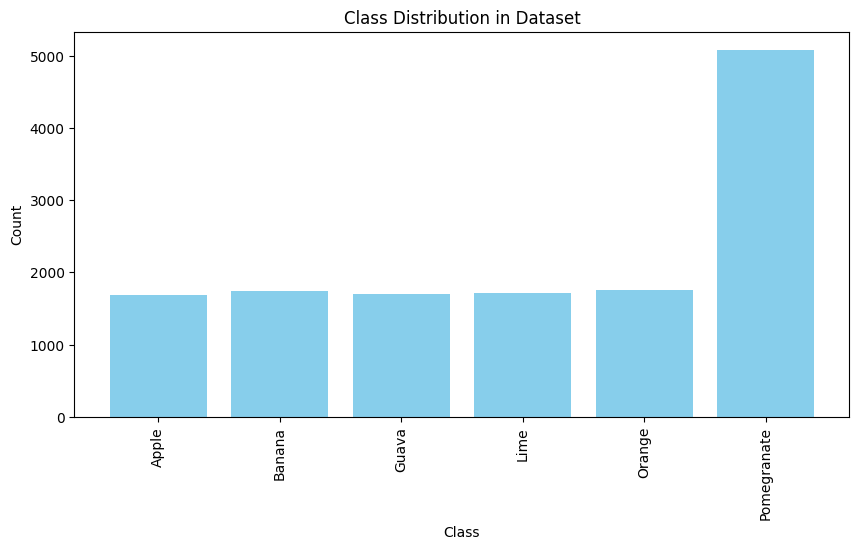

In [13]:
# Dataset Analysis
# Class distribution plot

import os
import matplotlib.pyplot as plt
import pandas as pd

# Use the dynamically resolved train_csv from the Dataloaders setup if available
try:
    # fallback if train_csv variable is not defined in the workspace yet
    path_to_check = train_csv
except NameError:
    path_to_check = "/content/drive/MyDrive/Fruit_Classification_project/splits/train.csv"

if not os.path.exists(path_to_check):
    print(f"[ERROR] Cannot plot class distribution because the file was not found at:\n{path_to_check}")
    print("Please verify your Google Drive dataset folder upload and ensure you have run the Dataloader cell successfully.")
else:
    # Read the training dataset
    dataset_df = pd.read_csv(path_to_check)

    # Get the counts for each class
    class_counts = dataset_df["fruit"].value_counts()

    # Define class order
    classes = [
        "Apple",
        "Banana",
        "Guava",
        "Lime",
        "Orange",
        "Pomegranate"
    ]

    # Get class counts
    counts = [
        class_counts.get(cls, 0)
        for cls in classes
    ]

    # Create a bar plot
    plt.figure(figsize=(10, 5))

    plt.bar(
        classes,
        counts,
        color="skyblue"
    )

    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.title("Class Distribution in Dataset")

    plt.xticks(rotation=90)

    plt.show()

Before CutMix/MixUp: images.shape = torch.Size([8, 3, 224, 224]), labels.shape = torch.Size([8])
After CutMix/MixUp: images_augmented.shape = torch.Size([8, 3, 224, 224]), labels_augmented.shape = torch.Size([8, 6])


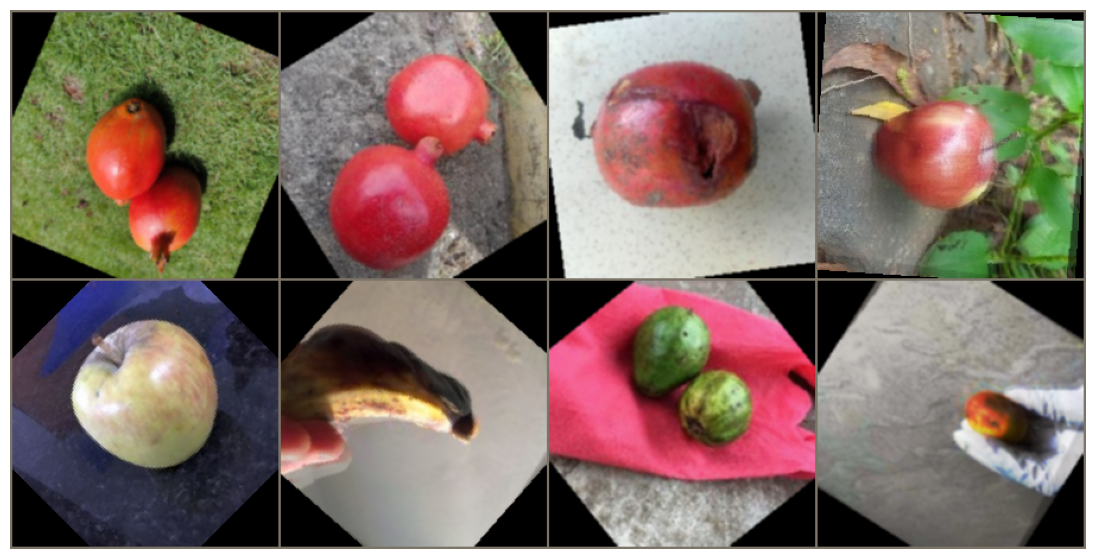

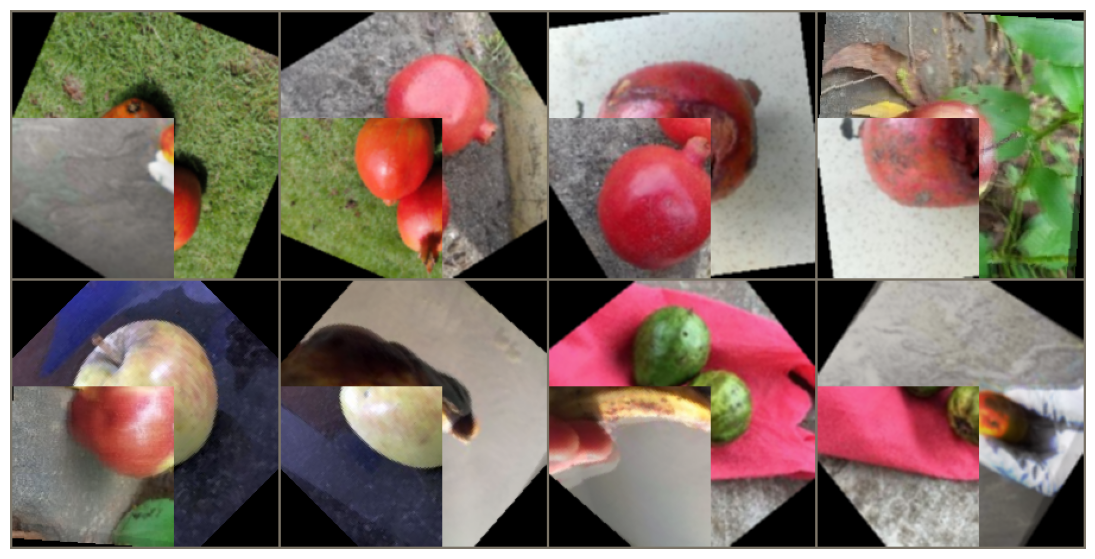

In [16]:
# CutMix / MixUp Visualization

from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import numpy as np
import torch
from torchvision.transforms import v2

NUM_CLASSES = 6

# Fix the image paths in the dataset dataframe to match the correct project path with underscores
if hasattr(f_train_dataset, 'dataframe'):
    f_train_dataset.dataframe['image_path'] = f_train_dataset.dataframe['image_path'].str.replace(
        '/content/drive/MyDrive/Fruit Classification project/',
        '/content/drive/MyDrive/Fruit_Classification_project/',
        regex=False
    )

# Use batch size = 8
dataloader = DataLoader(
    f_train_dataset,
    batch_size=8,
    shuffle=True
)


# Define CutMix
cutmix = v2.CutMix(
    num_classes=NUM_CLASSES
)


# Define MixUp
mixup = v2.MixUp(
    num_classes=NUM_CLASSES
)


# Randomly choose CutMix or MixUp
cutmix_or_mixup = v2.RandomChoice([
    cutmix,
    mixup
])


# Denormalize images for visualization
def denormalize(img):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    return torch.clamp(
        img * std + mean,
        0,
        1
    )


def show(img):

    img = denormalize(img)

    npimg = img.numpy()

    plt.figure(figsize=(15, 7))

    plt.imshow(
        np.transpose(npimg, (1, 2, 0))
    )

    plt.axis('off')

    plt.show()


# Look at one batch
for images, labels in dataloader:

    print(
        f"Before CutMix/MixUp: "
        f"{images.shape = }, "
        f"{labels.shape = }"
    )

    images_augmented, labels_augmented = (
        cutmix_or_mixup(images, labels)
    )

    print(
        f"After CutMix/MixUp: "
        f"{images_augmented.shape = }, "
        f"{labels_augmented.shape = }"
    )

    # Visualize original images
    show(
        make_grid(
            images,
            nrow=4
        )
    )

    # Visualize CutMix/MixUp images
    show(
        make_grid(
            images_augmented,
            nrow=4
        )
    )

    break

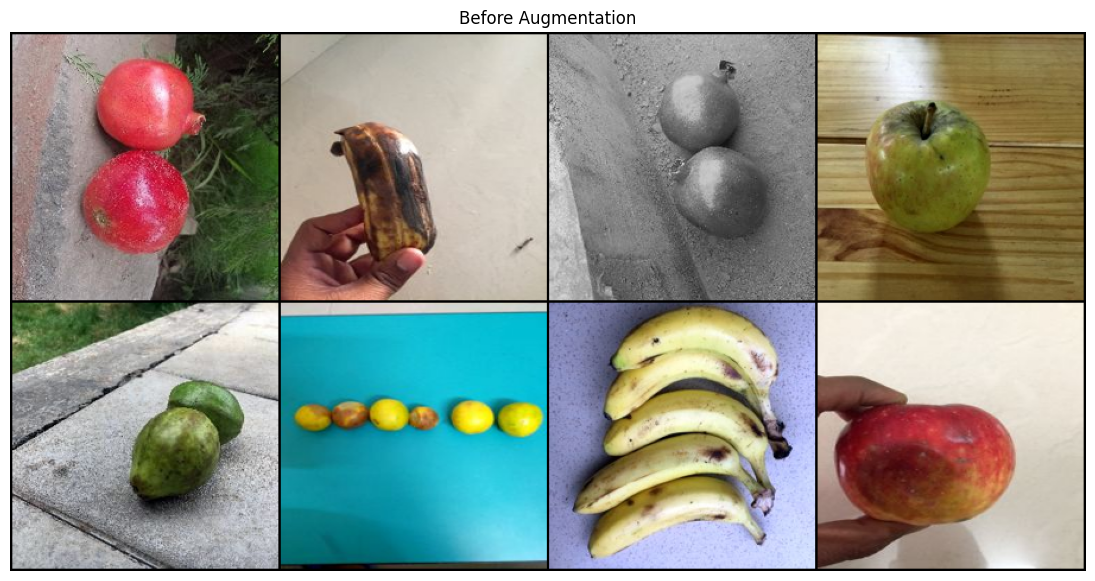

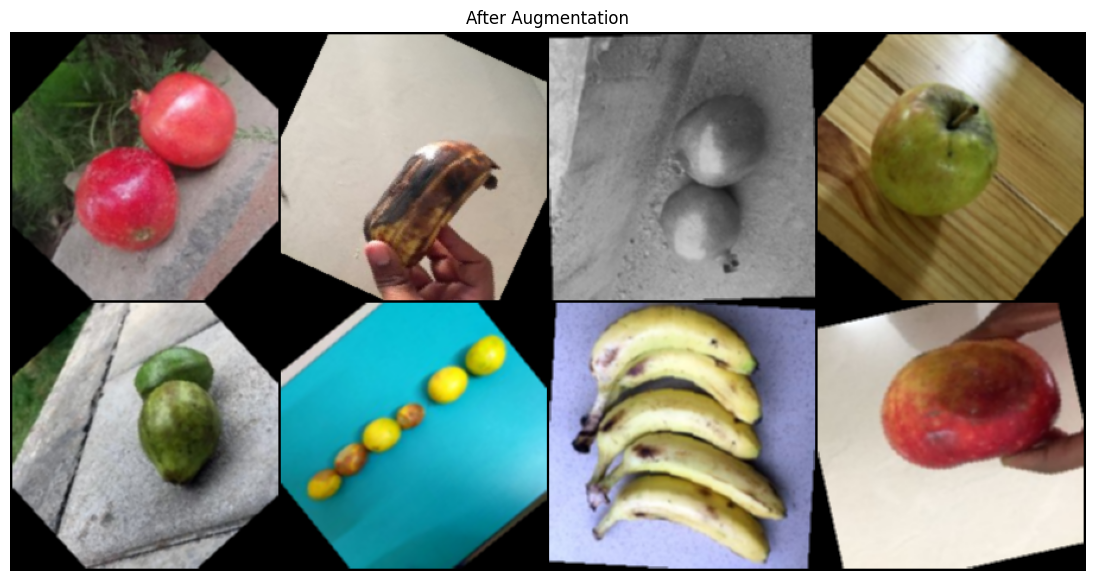

In [17]:
# Before and after augmentation

import matplotlib.pyplot as plt
import torchvision
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import DataLoader, Dataset


# ------------------------------------------------------------
# Display function
# ------------------------------------------------------------

def imshow(inp, title=None):

    inp = inp.numpy().transpose((1, 2, 0))

    plt.figure(figsize=(15, 7))
    plt.imshow(inp)

    if title is not None:
        plt.title(title)

    plt.axis("off")
    plt.show()


# ------------------------------------------------------------
# Dataset without augmentation
# ------------------------------------------------------------

class NoAugCSVFruitDataset(Dataset):

    def __init__(self, csv_path):

        self.dataframe = pd.read_csv(csv_path)

        # Standardize the image paths to match the correct project directory name
        self.dataframe["image_path"] = self.dataframe["image_path"].str.replace(
            "/content/drive/MyDrive/Fruit Classification project/",
            "/content/drive/MyDrive/Fruit_Classification_project/",
            regex=False
        ).str.replace(
            "/content/drive/MyDrive/Fruit_Classification_Project/",
            "/content/drive/MyDrive/Fruit_Classification_project/",
            regex=False
        )

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        image = Image.open(
            image_path
        ).convert("RGB")

        # Necessary so all images have the same size
        image = image.resize((224, 224))

        image = torchvision.transforms.functional.to_tensor(
            image
        )

        return image, row["fruit"]


# ------------------------------------------------------------
# Before Augmentation
# ------------------------------------------------------------

noaug_train_dataset = NoAugCSVFruitDataset(
    train_csv
)

noaugdataloader = DataLoader(
    noaug_train_dataset,
    batch_size=8,
    shuffle=False
)


# Get one batch
b_inputs, b_classes = next(
    iter(noaugdataloader)
)


# Make a grid
b_out = torchvision.utils.make_grid(
    b_inputs,
    nrow=4
)


# Display
imshow(
    b_out,
    title="Before Augmentation"
)


# ------------------------------------------------------------
# After Augmentation
# ------------------------------------------------------------

# Ensure paths are corrected in f_train_dataset or the CSVFruitDataset dataframe as well
if hasattr(f_train_dataset, 'dataframe'):
    f_train_dataset.dataframe['image_path'] = f_train_dataset.dataframe['image_path'].str.replace(
        '/content/drive/MyDrive/Fruit Classification project/',
        '/content/drive/MyDrive/Fruit_Classification_project/',
        regex=False
    ).str.replace(
        '/content/drive/MyDrive/Fruit_Classification_Project/',
        '/content/drive/MyDrive/Fruit_Classification_project/',
        regex=False
    )

aug_train_dataset = CSVFruitDataset(
    train_csv,
    transform=transform,
    balance=None,
    target="fruit"
)

if hasattr(aug_train_dataset, 'dataframe'):
    aug_train_dataset.dataframe['image_path'] = aug_train_dataset.dataframe['image_path'].str.replace(
        '/content/drive/MyDrive/Fruit Classification project/',
        '/content/drive/MyDrive/Fruit_Classification_project/',
        regex=False
    ).str.replace(
        '/content/drive/MyDrive/Fruit_Classification_Project/',
        '/content/drive/MyDrive/Fruit_Classification_project/',
        regex=False
    )

augdataloader = DataLoader(
    aug_train_dataset,
    batch_size=8,
    shuffle=False
)


# Get one batch
t_inputs, t_classes = next(
    iter(augdataloader)
)


# ------------------------------------------------------------
# Denormalize for visualization
# ------------------------------------------------------------

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)

t_inputs_display = torch.clamp(
    t_inputs * std + mean,
    0,
    1
)


# Make a grid
t_out = torchvision.utils.make_grid(
    t_inputs_display,
    nrow=4
)


# Display
imshow(
    t_out,
    title="After Augmentation"
)

In [13]:
# TensorBoard

%load_ext tensorboard

from datetime import datetime
import uuid
from torch.utils.tensorboard import SummaryWriter


# Get the current date and time
now = datetime.now()

# Format date as a string
now_str = now.strftime("%Y%m%d-%H%M%S")

# Create a unique identifier for this run
unique_id = uuid.uuid4().hex

# Specify a folder for run logs
log_dir = f'/content/drive/MyDrive/log/{now_str}_{unique_id}'

# Create TensorBoard writer
writer = SummaryWriter(log_dir)

print("TensorBoard log directory:")
print(log_dir)

TensorBoard log directory:
/content/drive/MyDrive/log/20261006-114423_f1ea14ca5f5f49f09129a4aa18411ce9


In [14]:
# EfficientNetV2 Model

# Load pre-trained model
from torchvision.models import efficientnet_v2_s

model = efficientnet_v2_s(
    weights='IMAGENET1K_V1',
    progress=True
)

print(model)

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 170MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  

In [18]:
# Fruit Type Classification Model

import os
import copy
import glob
import torch
import torch.optim as optim
from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from torch.utils.tensorboard import SummaryWriter
from torchvision.models import efficientnet_v2_s
from torchvision.transforms import v2
from tqdm.auto import tqdm
import numpy as np

# ============================================================
# Guard Checks: Ensure Dataloaders are initialized first
# ============================================================
required_vars = [
    'f_train_dataset', 'f_val_dataset', 'f_test_dataset',
    'q_train_dataset', 'q_val_dataset', 'q_test_dataset',
    'f_train_loader', 'f_val_loader'
]
missing_vars = [var for var in required_vars if var not in globals()]

if missing_vars:
    print("[ERROR] Cannot start training because the required datasets/dataloaders are not initialized.")
    print("Please make sure you have:")
    print(" 1. Uploaded your dataset folder (with 'splits/train.csv') directly to Google Drive.")
    print(" 2. Successfully executed the Dataloaders cell (cell_id: Yuiyd1_-8-ph).")
else:
    # ============================================================
    # Load EfficientNetV2-S
    # ============================================================

    model = efficientnet_v2_s(
        weights='IMAGENET1K_V1',
        progress=True
    )

    # ============================================================
    # Number of classes
    # ============================================================

    num_classes = 6

    # ============================================================
    # CutMix and MixUp
    # ============================================================

    cutmix = v2.CutMix(
        num_classes=num_classes
    )

    mixup = v2.MixUp(
        num_classes=num_classes
    )

    cutmix_or_mixup = v2.RandomChoice(
        [cutmix, mixup]
    )

    # ============================================================
    # Modify the final classification layer
    # ============================================================

    num_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        num_features,
        num_classes
    )

    # ============================================================
    # Loss function
    # ============================================================

    criterion = nn.CrossEntropyLoss()

    # ============================================================
    # Optimizer
    # Learning Rate = 0.01
    # ============================================================

    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.01,
        weight_decay=1e-2
    )

    # ============================================================
    # Learning-rate scheduler
    # ============================================================

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=3
    )

    # ============================================================
    # Device
    # ============================================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Using device:", device)

    model = model.to(device)

    # ============================================================
    # Checkpoint directory
    # ============================================================

    checkpoint_dir = "/content/drive/MyDrive/fruitcheckpoints"

    os.makedirs(
        checkpoint_dir,
        exist_ok=True
    )

    print("Checkpoint directory:")
    print(checkpoint_dir)

    # ============================================================
    # Path cleaning for all datasets
    # ============================================================

    def clean_dataset_paths(dataset):
        if hasattr(dataset, 'dataframe'):
            dataset.dataframe['image_path'] = dataset.dataframe['image_path'].str.replace(
                '/content/drive/MyDrive/Fruit Classification project/',
                '/content/drive/MyDrive/Fruit_Classification_project/',
                regex=False
            ).str.replace(
                '/content/drive/MyDrive/Fruit_Classification_Project/',
                '/content/drive/MyDrive/Fruit_Classification_project/',
                regex=False
            )

    clean_dataset_paths(f_train_dataset)
    clean_dataset_paths(f_val_dataset)
    clean_dataset_paths(f_test_dataset)
    clean_dataset_paths(q_train_dataset)
    clean_dataset_paths(q_val_dataset)
    clean_dataset_paths(q_test_dataset)

    # ============================================================
    # Training settings
    # ============================================================

    num_epochs = 30

    start_epoch = 0

    best_val_accuracy = -np.inf

    best_model_state = copy.deepcopy(
        model.state_dict()
    )

    # ============================================================
    # Automatically find the latest checkpoint
    # ============================================================

    checkpoint_files = glob.glob(
        os.path.join(
            checkpoint_dir,
            "checkpoint_*.pth"
        )
    )

    if checkpoint_files:
        # Sort checkpoint files according to epoch number
        checkpoint_files.sort(
            key=lambda x: int(
                os.path.basename(x)
                .split("_")[-1]
                .split(".")[0]
            )
        )

        latest_checkpoint = checkpoint_files[-1]

        print("\nCheckpoint found:")
        print(latest_checkpoint)

        print("\nLoading checkpoint...")

        checkpoint = torch.load(
            latest_checkpoint,
            map_location=device
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

        start_epoch = checkpoint["epoch"] + 1

        if "best_val_accuracy" in checkpoint:
            best_val_accuracy = checkpoint[
                "best_val_accuracy"
            ]

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        print("Checkpoint loaded successfully.")
        print(f"Resuming from Epoch {start_epoch + 1}")
    else:
        print("\nNo checkpoint found.")
        print("Starting training from Epoch 1.")

    # ============================================================
    # Training
    # ============================================================

    for epoch in range(
        start_epoch,
        num_epochs
    ):
        # Training mode
        model.train()
        running_loss = 0.0
        all_train_preds = []
        all_train_labels = []

        # Training progress bar
        train_progress = tqdm(
            enumerate(f_train_loader),
            total=len(f_train_loader),
            desc=f"Epoch {epoch + 1}/{num_epochs} - Training",
            unit="batch"
        )

        # Training batches
        for i, data in train_progress:
            inputs = data[0].to(device)
            labels = data[1].to(device)

            # Apply CutMix or MixUp
            inputs, labels = cutmix_or_mixup(
                inputs,
                labels
            )

            # Zero gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(inputs)

            # Calculate loss
            loss = criterion(
                outputs,
                labels
            )

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Convert soft labels to hard labels
            hard_labels = torch.argmax(
                labels,
                dim=1
            )
            _, preds = torch.max(
                outputs,
                1
            )

            all_train_preds.extend(
                preds.detach().cpu().numpy()
            )
            all_train_labels.extend(
                hard_labels.detach().cpu().numpy()
            )

            # Running loss
            running_loss += loss.item()

            # Calculate current percentage
            progress_percent = (
                (i + 1) /
                len(f_train_loader)
            ) * 100

            # Update progress bar
            train_progress.set_postfix(
                loss=f"{loss.item():.4f}",
                progress=f"{progress_percent:.1f}%"
            )

        # Average training loss
        running_loss = (
            running_loss /
            len(f_train_loader)
        )

        # Training accuracy
        train_accuracy = accuracy_score(
            all_train_labels,
            all_train_preds
        )

        print(
            f"\nEpoch {epoch + 1} "
            f"loss: {running_loss:.3f}, "
            f"training accuracy: {train_accuracy:.3f}"
        )

        # TensorBoard
        writer.add_scalar(
            'Training Loss',
            running_loss,
            epoch
        )
        writer.add_scalar(
            'Training Accuracy',
            train_accuracy,
            epoch
        )

        # ========================================================
        # Validation
        # ========================================================

        model.eval()
        val_loss = 0.0
        all_preds = []
        all_labels = []

        # Validation progress bar
        val_progress = tqdm(
            enumerate(f_val_loader),
            total=len(f_val_loader),
            desc=f"Epoch {epoch + 1}/{num_epochs} - Validation",
            unit="batch"
        )

        # Validation batches
        with torch.no_grad():
            for i, val_data in val_progress:
                val_inputs = val_data[0].to(device)
                val_labels = val_data[1].to(device)

                # Forward pass
                val_outputs = model(
                    val_inputs
                )

                # Validation loss
                batch_val_loss = criterion(
                    val_outputs,
                    val_labels
                ).item()

                val_loss += batch_val_loss

                # Predictions
                _, preds = torch.max(
                    val_outputs,
                    1
                )

                all_preds.extend(
                    preds.cpu().numpy()
                )
                all_labels.extend(
                    val_labels.cpu().numpy()
                )

                # Validation percentage
                progress_percent = (
                    (i + 1) /
                    len(f_val_loader)
                ) * 100

                val_progress.set_postfix(
                    loss=f"{batch_val_loss:.4f}",
                    progress=f"{progress_percent:.1f}%"
                )

        # Average validation loss
        val_loss = (
            val_loss /
            len(f_val_loader)
        )

        # Validation accuracy
        val_accuracy = accuracy_score(
            all_labels,
            all_preds
        )

        print(
            f"\nEpoch {epoch + 1} "
            f"validation loss: {val_loss:.3f}, "
            f"validation accuracy: {val_accuracy:.3f}"
        )

        # TensorBoard validation metrics
        writer.add_scalar(
            'Validation Loss',
            val_loss,
            epoch
        )
        writer.add_scalar(
            'Validation Accuracy',
            val_accuracy,
            epoch
        )

        # ========================================================
        # Save checkpoint
        # ========================================================

        checkpoint_path = os.path.join(
            checkpoint_dir,
            f"checkpoint_{epoch}.pth"
        )

        torch.save(
            {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'loss': val_loss,
                'best_val_accuracy': best_val_accuracy
            },
            checkpoint_path
        )

        print(f"Checkpoint saved: {checkpoint_path}")

        # ========================================================
        # Check best model
        # ========================================================

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            # Save best model separately
            best_model_path = os.path.join(
                checkpoint_dir,
                "best_model.pth"
            )

            torch.save(
                {
                    'epoch': epoch,
                    'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scheduler_state_dict': scheduler.state_dict(),
                    'best_val_accuracy': best_val_accuracy
                },
                best_model_path
            )

            print(f"Best model saved. Validation accuracy: {best_val_accuracy:.4f}")

        # ========================================================
        # Scheduler
        # ========================================================

        scheduler.step(
            val_loss
        )

        # Current learning rate
        current_lr = optimizer.param_groups[0]["lr"]
        print(f"Current learning rate: {current_lr}")

    print("\nFinished Training")
    print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")


Using device: cuda
Checkpoint directory:
/content/drive/MyDrive/fruitcheckpoints

Checkpoint found:
/content/drive/MyDrive/fruitcheckpoints/checkpoint_29.pth

Loading checkpoint...
Checkpoint loaded successfully.
Resuming from Epoch 31

Finished Training
Best Validation Accuracy: 0.9188


In [15]:
import os
import shutil

source = "/content/drive/MyDrive/fruitcheckpoints/best_model.pth"
destination_dir = "/content/drive/MyDrive/MFC"
destination = os.path.join(destination_dir, "MFC.pth")

os.makedirs(destination_dir, exist_ok=True)

shutil.copy2(source, destination)

print("Best model copied successfully.")
print("Saved at:", destination)

Best model copied successfully.
Saved at: /content/drive/MyDrive/MFC/MFC.pth


Using device: cuda
Checkpoint loaded successfully.
Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val_accuracy'])
Model weights loaded successfully.
Fruit label mapping:
{0: 'Apple', 1: 'Banana', 2: 'Guava', 3: 'Lime', 4: 'Orange', 5: 'Pomegranate'}

Fruit Type Classification Results
Fruit type model accuracy: 0.9216589861751152
Fruit type model accuracy (%): 92.16589861751152
Average inference time per sample: 0.004980084106242175 seconds
Number of test samples: 1953


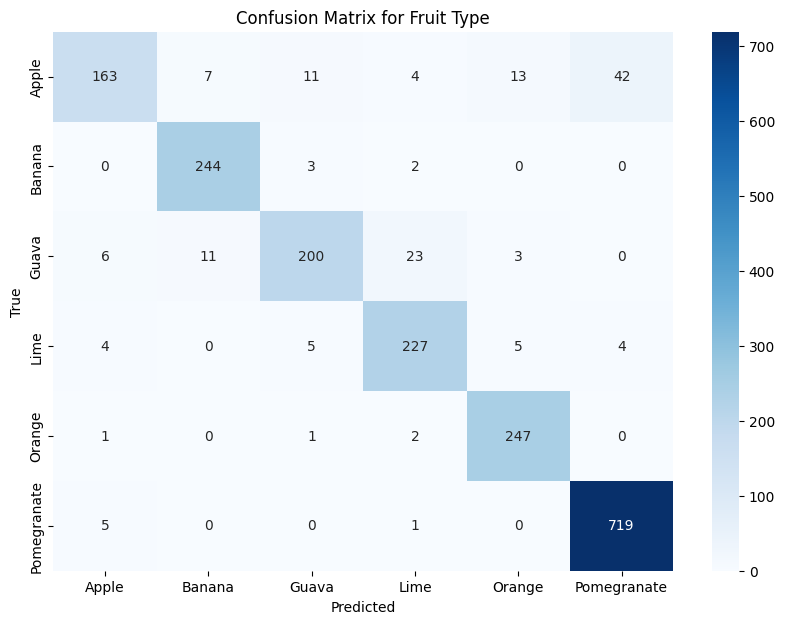

In [19]:
# ============================================================
# Test Fruit Type Classification Model
# Based on the base-paper testing code
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import efficientnet_v2_s
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import time

# ------------------------------------------------------------
# 1. Define device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# ------------------------------------------------------------
# 2. Define EfficientNetV2-S model
# ------------------------------------------------------------

model_fruit_type = efficientnet_v2_s(
    weights='IMAGENET1K_V1',
    progress=True
)


# ------------------------------------------------------------
# 3. Modify final layer for 6 fruit classes
# ------------------------------------------------------------

num_classes_type = 6

model_fruit_type.classifier[1] = nn.Linear(
    model_fruit_type.classifier[1].in_features,
    num_classes_type
)


# ------------------------------------------------------------
# 4. Load the saved checkpoint
# ------------------------------------------------------------

model_path = "/content/drive/MyDrive/MFC/MFC.pth"

checkpoint = torch.load(
    model_path,
    map_location=device
)

print("Checkpoint loaded successfully.")

print("Checkpoint keys:")
print(checkpoint.keys())


# ------------------------------------------------------------
# 5. Load ONLY the model weights from the checkpoint
# ------------------------------------------------------------

model_fruit_type.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Model weights loaded successfully.")


# ------------------------------------------------------------
# 6. Move model to device
# ------------------------------------------------------------

model_fruit_type = model_fruit_type.to(device)


# ------------------------------------------------------------
# 7. Define fruit-label mapping
# ------------------------------------------------------------

# Your CSV dataset should contain the fruit_to_idx mapping.
#
# Example:
# Apple        -> 0
# Banana       -> 1
# Guava        -> 2
# Lime         -> 3
# Orange       -> 4
# Pomegranate  -> 5

idx_to_fruit = {
    v: k for k, v in f_test_dataset.fruit_to_idx.items()
}

print("Fruit label mapping:")
print(idx_to_fruit)


# ------------------------------------------------------------
# 8. Store true and predicted labels
# ------------------------------------------------------------

true_fruit_labels = []
predicted_fruit_labels = []


# ------------------------------------------------------------
# 9. Set model to evaluation mode
# ------------------------------------------------------------

model_fruit_type.eval()


# ------------------------------------------------------------
# 10. Initialize inference-time variables
# ------------------------------------------------------------

total_inference_time_fruit_type = 0

num_samples = 0


# ------------------------------------------------------------
# 11. Predict fruit type for every test image
# ------------------------------------------------------------

for i, data in enumerate(f_test_loader, 0):

    inputs = data[0].to(device)
    fruit_labels = data[1].to(device)

    num_samples += inputs.size(0)

    # Start inference timer
    start_time = time.time()

    with torch.no_grad():

        outputs_fruit_type = model_fruit_type(inputs)

        _, predicted_fruit_type = torch.max(
            outputs_fruit_type,
            1
        )

    # End inference timer
    end_time = time.time()

    total_inference_time_fruit_type += (
        end_time - start_time
    )

    # Store true labels
    true_fruit_labels.extend(
        fruit_labels.cpu().numpy()
    )

    # Store predicted labels
    predicted_fruit_labels.extend(
        predicted_fruit_type.cpu().numpy()
    )


# ------------------------------------------------------------
# 12. Calculate fruit-type accuracy
# ------------------------------------------------------------

fruit_type_accuracy = accuracy_score(
    true_fruit_labels,
    predicted_fruit_labels
)


# ------------------------------------------------------------
# 13. Calculate average inference time
# ------------------------------------------------------------

average_inference_time_per_sample_fruit_type = (
    total_inference_time_fruit_type / num_samples
)


# ------------------------------------------------------------
# 14. Print results
# ------------------------------------------------------------

print()
print("==============================================")
print("Fruit Type Classification Results")
print("==============================================")

print(
    "Fruit type model accuracy:",
    fruit_type_accuracy
)

print(
    "Fruit type model accuracy (%):",
    fruit_type_accuracy * 100
)

print(
    "Average inference time per sample:",
    average_inference_time_per_sample_fruit_type,
    "seconds"
)

print(
    "Number of test samples:",
    num_samples
)


# ------------------------------------------------------------
# 15. Calculate confusion matrix
# ------------------------------------------------------------

fruit_type_cm = confusion_matrix(
    true_fruit_labels,
    predicted_fruit_labels
)


# ------------------------------------------------------------
# 16. Plot confusion matrix
# ------------------------------------------------------------

fruit_type_classes = [
    idx_to_fruit[i]
    for i in range(len(idx_to_fruit))
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    fruit_type_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=fruit_type_classes,
    yticklabels=fruit_type_classes
)

plt.xlabel('Predicted')
plt.ylabel('True')

plt.title(
    'Confusion Matrix for Fruit Type'
)

plt.show()

In [20]:
from sklearn.metrics import classification_report

# Generate the classification report
fruit_type_report = classification_report(
    true_fruit_labels,
    predicted_fruit_labels,
    target_names=fruit_type_classes
)

# Print the classification report
print('Classification report for Fruit Type Model:')
print(fruit_type_report)

Classification report for Fruit Type Model:
              precision    recall  f1-score   support

       Apple       0.91      0.68      0.78       240
      Banana       0.93      0.98      0.95       249
       Guava       0.91      0.82      0.86       243
        Lime       0.88      0.93      0.90       245
      Orange       0.92      0.98      0.95       251
 Pomegranate       0.94      0.99      0.97       725

    accuracy                           0.92      1953
   macro avg       0.91      0.90      0.90      1953
weighted avg       0.92      0.92      0.92      1953



In [18]:
# ============================================================
# QUALITY CLASSIFICATION MODEL
# Base-paper code + progress percentage + checkpoint resume
# ============================================================

import os
import torch
import torch.optim as optim
from torch import nn
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from torch.utils.tensorboard import SummaryWriter
import numpy as np
from torchvision.models import efficientnet_v2_s
from torchvision.transforms import v2
from tqdm.auto import tqdm


# ============================================================
# 1. Define device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
# 2. Define number of classes
# ============================================================

num_fruit_classes = 6
num_quality_classes = 3


# ============================================================
# 3. Create EfficientNetV2-S
# ============================================================

model = efficientnet_v2_s(
    weights='IMAGENET1K_V1',
    progress=True
)


# ============================================================
# 4. Change classifier to 6 fruit classes
# ============================================================

# 🔧 Necessary modification:
# MFC.pth contains weights for 6 fruit classes.
# The default EfficientNetV2-S has 1000 ImageNet classes.
#
# Therefore, the classifier must first be changed from:
# 1000 classes -> 6 fruit classes.

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    num_fruit_classes
)


# ============================================================
# 5. Load the saved fruit classification model
# ============================================================

fruit_model_path = (
    "/content/drive/MyDrive/MFC/MFC.pth"
)

fruit_checkpoint = torch.load(
    fruit_model_path,
    map_location=device
)

print("Fruit classification checkpoint loaded.")

print("Checkpoint keys:")
print(fruit_checkpoint.keys())


# ============================================================
# 6. Load fruit classification weights
# ============================================================

model.load_state_dict(
    fruit_checkpoint["model_state_dict"]
)

print(
    "Fruit classification weights loaded successfully."
)


# ============================================================
# 7. Define CutMix and MixUp
# ============================================================

cutmix = v2.CutMix(
    num_classes=num_quality_classes
)

mixup = v2.MixUp(
    num_classes=num_quality_classes
)

cutmix_or_mixup = v2.RandomChoice([
    cutmix,
    mixup
])


# ============================================================
# 8. Change classifier to 3 quality classes
# ============================================================

# Now transfer the learned fruit features to the
# quality classification task.

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    num_quality_classes
)

print(
    "Final classifier changed to",
    num_quality_classes,
    "quality classes."
)


# ============================================================
# 9. Move model to device
# ============================================================

model = model.to(device)


# ============================================================
# 10. Define loss function
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# 11. Define optimizer
# ============================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-2
)


# ============================================================
# 12. Define learning-rate scheduler
# ============================================================

# 🔧 Necessary modification:
# Current PyTorch does not support verbose=True.

scheduler = ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=3
)


# ============================================================
# 13. Create quality checkpoint directory
# ============================================================

checkpoint_dir = (
    "/content/drive/MyDrive/qualitycheckpoints"
)

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)

print(
    "Checkpoint directory:",
    checkpoint_dir
)


# ============================================================
# 14. TensorBoard writer
# ============================================================

log_dir = (
    "/content/drive/MyDrive/log/quality_classification"
)

os.makedirs(
    log_dir,
    exist_ok=True
)

writer = SummaryWriter(
    log_dir=log_dir
)


# ============================================================
# 15. Training configuration
# ============================================================

num_epochs = 30

start_epoch = 0

best_val_accuracy = -np.inf


# ============================================================
# 16. Find latest quality checkpoint
# ============================================================

checkpoint_files = []

for file in os.listdir(checkpoint_dir):

    if (
        file.startswith("checkpoint_")
        and file.endswith(".pth")
    ):

        checkpoint_files.append(file)


if checkpoint_files:

    checkpoint_files.sort(
        key=lambda x: int(
            x.replace("checkpoint_", "")
             .replace(".pth", "")
        )
    )

    latest_checkpoint = checkpoint_files[-1]

    latest_checkpoint_path = os.path.join(
        checkpoint_dir,
        latest_checkpoint
    )

    print()
    print(
        "Latest quality checkpoint found:"
    )

    print(
        latest_checkpoint_path
    )


    # --------------------------------------------------------
    # Load quality checkpoint
    # --------------------------------------------------------

    resume_checkpoint = torch.load(
        latest_checkpoint_path,
        map_location=device
    )


    # --------------------------------------------------------
    # Restore model
    # --------------------------------------------------------

    model.load_state_dict(
        resume_checkpoint["model_state_dict"]
    )


    # --------------------------------------------------------
    # Restore optimizer
    # --------------------------------------------------------

    optimizer.load_state_dict(
        resume_checkpoint["optimizer_state_dict"]
    )


    # --------------------------------------------------------
    # Restore scheduler
    # --------------------------------------------------------

    if "scheduler_state_dict" in resume_checkpoint:

        scheduler.load_state_dict(
            resume_checkpoint["scheduler_state_dict"]
        )


    # --------------------------------------------------------
    # Restore epoch
    # --------------------------------------------------------

    start_epoch = (
        resume_checkpoint["epoch"] + 1
    )


    # --------------------------------------------------------
    # Restore best accuracy
    # --------------------------------------------------------

    if "best_val_accuracy" in resume_checkpoint:

        best_val_accuracy = (
            resume_checkpoint[
                "best_val_accuracy"
            ]
        )


    print(
        f"Resuming from epoch "
        f"{start_epoch + 1}"
    )

else:

    print()
    print(
        "No previous quality checkpoint found."
    )

    print(
        "Starting quality training from epoch 1."
    )


# ============================================================
# 17. Training loop
# ============================================================

for epoch in range(
    start_epoch,
    num_epochs
):

    # ========================================================
    # Training
    # ========================================================

    model.train()

    running_loss = 0.0

    all_train_preds = []

    all_train_labels = []


    print()
    print(
        f"Epoch {epoch + 1}/{num_epochs} - Training"
    )


    train_progress = tqdm(
        q_train_loader,
        total=len(q_train_loader),
        desc=(
            f"Epoch {epoch + 1}/{num_epochs} "
            f"- Training"
        ),
        unit="batch"
    )


    for i, data in enumerate(
        train_progress,
        0
    ):

        # ----------------------------------------------------
        # Get inputs and labels
        # ----------------------------------------------------

        inputs = data[0].to(device)

        labels = data[1].to(device)


        # ----------------------------------------------------
        # Apply CutMix or MixUp
        # ----------------------------------------------------

        inputs, labels = cutmix_or_mixup(
            inputs,
            labels
        )


        # ----------------------------------------------------
        # Zero gradients
        # ----------------------------------------------------

        optimizer.zero_grad()


        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        outputs = model(inputs)


        # ----------------------------------------------------
        # Calculate loss
        # ----------------------------------------------------

        loss = criterion(
            outputs,
            labels
        )


        # ----------------------------------------------------
        # Backward pass
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # Update model
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # Convert soft labels to hard labels
        # ----------------------------------------------------

        hard_labels = torch.argmax(
            labels,
            dim=1
        )


        # ----------------------------------------------------
        # Predictions
        # ----------------------------------------------------

        _, preds = torch.max(
            outputs,
            1
        )


        # ----------------------------------------------------
        # Store predictions
        # ----------------------------------------------------

        all_train_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_train_labels.extend(
            hard_labels.detach().cpu().numpy()
        )


        # ----------------------------------------------------
        # Running loss
        # ----------------------------------------------------

        running_loss += loss.item()


        # ----------------------------------------------------
        # Progress percentage
        # ----------------------------------------------------

        progress_percent = (
            (i + 1)
            / len(q_train_loader)
        ) * 100


        train_progress.set_postfix(
            loss=f"{loss.item():.4f}",
            progress=f"{progress_percent:.1f}%"
        )


    # ========================================================
    # Training metrics
    # ========================================================

    running_loss = (
        running_loss
        / len(q_train_loader)
    )

    train_accuracy = accuracy_score(
        all_train_labels,
        all_train_preds
    )


    print(
        f"Epoch {epoch + 1} loss: "
        f"{running_loss:.3f}, "
        f"training accuracy: "
        f"{train_accuracy:.3f}"
    )


    # ========================================================
    # TensorBoard
    # ========================================================

    writer.add_scalar(
        "Training Loss",
        running_loss,
        epoch
    )

    writer.add_scalar(
        "Training Accuracy",
        train_accuracy,
        epoch
    )


    # ========================================================
    # Validation
    # ========================================================

    model.eval()

    val_loss = 0.0

    all_preds = []

    all_labels = []


    print()
    print(
        f"Epoch {epoch + 1}/{num_epochs} - Validation"
    )


    val_progress = tqdm(
        q_val_loader,
        total=len(q_val_loader),
        desc=(
            f"Epoch {epoch + 1}/{num_epochs} "
            f"- Validation"
        ),
        unit="batch"
    )


    with torch.no_grad():

        for i, val_data in enumerate(
            val_progress,
            0
        ):

            val_inputs = (
                val_data[0].to(device)
            )

            val_labels = (
                val_data[1].to(device)
            )


            # ------------------------------------------------
            # Forward pass
            # ------------------------------------------------

            val_outputs = model(
                val_inputs
            )


            # ------------------------------------------------
            # Validation loss
            # ------------------------------------------------

            batch_val_loss = criterion(
                val_outputs,
                val_labels
            )


            val_loss += (
                batch_val_loss.item()
            )


            # ------------------------------------------------
            # Predictions
            # ------------------------------------------------

            _, preds = torch.max(
                val_outputs,
                1
            )


            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                val_labels.cpu().numpy()
            )


            # ------------------------------------------------
            # Progress percentage
            # ------------------------------------------------

            progress_percent = (
                (i + 1)
                / len(q_val_loader)
            ) * 100


            val_progress.set_postfix(
                loss=f"{batch_val_loss.item():.4f}",
                progress=f"{progress_percent:.1f}%"
            )


    # ========================================================
    # Validation metrics
    # ========================================================

    val_loss = (
        val_loss
        / len(q_val_loader)
    )

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )


    print(
        f"Epoch {epoch + 1} validation loss: "
        f"{val_loss:.3f}, "
        f"validation accuracy: "
        f"{val_accuracy:.3f}"
    )


    # ========================================================
    # TensorBoard validation metrics
    # ========================================================

    writer.add_scalar(
        "Validation Loss",
        val_loss,
        epoch
    )

    writer.add_scalar(
        "Validation Accuracy",
        val_accuracy,
        epoch
    )


    # ========================================================
    # Save best model
    # ========================================================

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_model.pth"
        )


        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_accuracy": best_val_accuracy
            },
            best_model_path
        )


        print(
            f"Best model saved. "
            f"Validation accuracy: "
            f"{best_val_accuracy:.4f}"
        )


    # ========================================================
    # Save checkpoint every epoch
    # ========================================================

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"checkpoint_{epoch}.pth"
    )


    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "loss": val_loss,
            "best_val_accuracy": best_val_accuracy
        },
        checkpoint_path
    )


    print(
        f"Checkpoint saved: "
        f"{checkpoint_path}"
    )


    # ========================================================
    # Scheduler
    # ========================================================

    scheduler.step(
        val_loss
    )


    # ========================================================
    # Current learning rate
    # ========================================================

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    print(
        f"Current learning rate: "
        f"{current_lr}"
    )


# ============================================================
# 18. Finished
# ============================================================

writer.close()

print()
print("==============================================")
print("Finished Quality Classification Training")
print("==============================================")

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

Using device: cuda
Fruit classification checkpoint loaded.
Checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val_accuracy'])
Fruit classification weights loaded successfully.
Final classifier changed to 3 quality classes.
Checkpoint directory: /content/drive/MyDrive/qualitycheckpoints

Latest quality checkpoint found:
/content/drive/MyDrive/qualitycheckpoints/checkpoint_17.pth
Resuming from epoch 19

Epoch 19/30 - Training


Epoch 19/30 - Training:   0%|          | 0/1709 [00:00<?, ?batch/s]

Epoch 19 loss: 0.488, training accuracy: 0.867

Epoch 19/30 - Validation


Epoch 19/30 - Validation:   0%|          | 0/489 [00:00<?, ?batch/s]

Epoch 19 validation loss: 0.184, validation accuracy: 0.956
Best model saved. Validation accuracy: 0.9560
Checkpoint saved: /content/drive/MyDrive/qualitycheckpoints/checkpoint_18.pth
Current learning rate: 0.001

Epoch 20/30 - Training


...

Epoch 29 validation loss: 0.171, validation accuracy: 0.959
Checkpoint saved: /content/drive/MyDrive/qualitycheckpoints/checkpoint_28.pth
Current learning rate: 0.0001

Epoch 30/30 - Training


Epoch 30/30 - Training:   0%|          | 0/1709 [00:00<?, ?batch/s]

Epoch 30 loss: 0.467, training accuracy: 0.878

Epoch 30/30 - Validation


Epoch 30/30 - Validation:   0%|          | 0/489 [00:00<?, ?batch/s]

Epoch 30 validation loss: 0.178, validation accuracy: 0.954
Checkpoint saved: /content/drive/MyDrive/qualitycheckpoints/checkpoint_29.pth
Current learning rate: 0.0001

Finished Quality Classification Training
Best Validation Accuracy: 0.9593


In [21]:
import os
import torch

# Create MFG folder
os.makedirs('/content/drive/MyDrive/MFG', exist_ok=True)

# Load the best quality-model checkpoint
checkpoint_path = '/content/drive/MyDrive/qualitycheckpoints/best_model.pth'

checkpoint = torch.load(
    checkpoint_path,
    map_location='cpu'
)

# Extract the trained model weights
best_model_state = checkpoint['model_state_dict']

# Save in the base-paper format/location
torch.save(
    best_model_state,
    '/content/drive/MyDrive/MFG/MFG.pth'
)

print("Best quality model saved successfully!")
print("Path: /content/drive/MyDrive/MFG/MFG.pth")

Best quality model saved successfully!
Path: /content/drive/MyDrive/MFG/MFG.pth


Device: cuda
GPU: Tesla T4

Searching for test.csv...
Test CSV found: /content/drive/MyDrive/Fruit_Classification_project/splits/test.csv

Test CSV columns:
['image_path', 'fruit', 'quality', 'combined_label']

Number of test samples: 1953

Project path: /content/drive/MyDrive/Fruit_Classification_project

Missing test images: 0
All test images found successfully.

Fruit mapping:
{'Apple': 0, 'Banana': 1, 'Guava': 2, 'Lime': 3, 'Orange': 4, 'Pomegranate': 5}

Quality mapping:
{'Good': 0, 'Bad': 1, 'Mixed': 2}

Test dataset size: 1953
Test batches: 245
Batch size: 8

Creating Fruit Classification Model...

Creating Quality Classification Model...

Loading MFC.pth...
MFC.pth loaded successfully.

Loading MFG.pth...
MFG.pth loaded successfully.

Both models are ready for testing.

Starting EfficientNetV2-S Model Testing


Testing:   0%|          | 0/245 [00:00<?, ?batch/s]


Testing completed successfully.

EfficientNetV2-S Testing Results

Fruit Type Model Accuracy: 0.9217
Fruit Type Model Accuracy: 92.17%

Fruit Type Weighted Precision: 0.9211
Fruit Type Weighted Recall: 0.9217
Fruit Type Weighted F1-score: 0.9185

Fruit Quality Model Accuracy: 0.9452
Fruit Quality Model Accuracy: 94.52%

Fruit Quality Weighted Precision: 0.9429
Fruit Quality Weighted Recall: 0.9452
Fruit Quality Weighted F1-score: 0.9425

Average Fruit Type Inference Time: 0.005984 seconds/sample
Average Quality Inference Time: 0.005198 seconds/sample

Fruit Type Classification Report
              precision    recall  f1-score   support

       Apple     0.9106    0.6792    0.7780       240
      Banana     0.9313    0.9799    0.9550       249
       Guava     0.9091    0.8230    0.8639       243
        Lime     0.8764    0.9265    0.9008       245
      Orange     0.9216    0.9841    0.9518       251
 Pomegranate     0.9399    0.9917    0.9651       725

    accuracy                

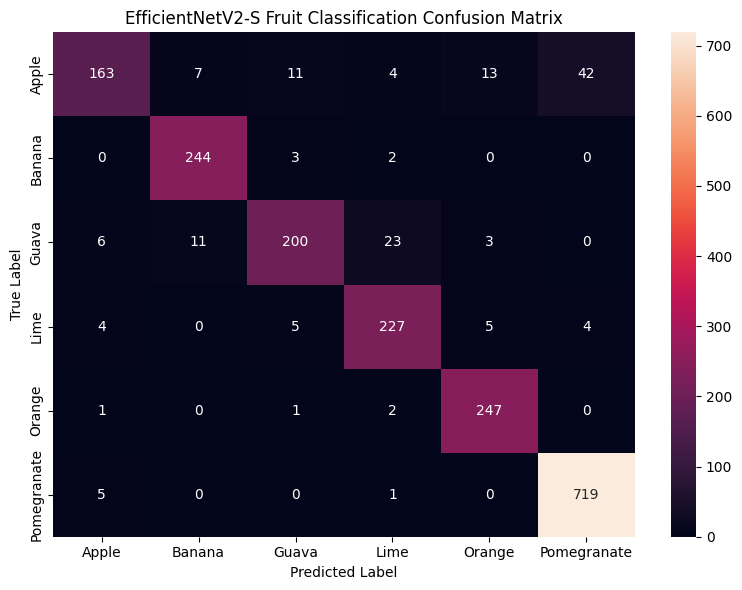

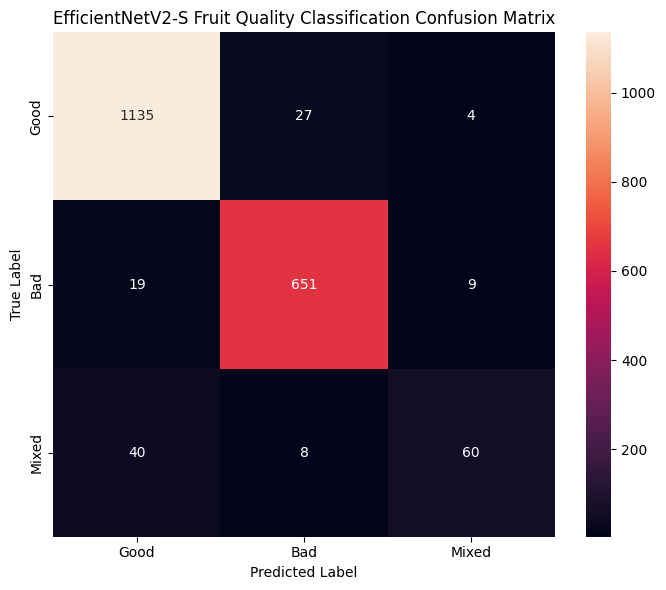


FINAL SUMMARY
Number of test samples: 1953
Fruit Type Test Accuracy: 92.17%
Fruit Type Weighted Precision: 92.11%
Fruit Type Weighted Recall: 92.17%
Fruit Type Weighted F1-score: 91.85%
Fruit Quality Test Accuracy: 94.52%
Fruit Quality Weighted Precision: 94.29%
Fruit Quality Weighted Recall: 94.52%
Fruit Quality Weighted F1-score: 94.25%
Fruit Type Inference Time: 0.005984 seconds/sample
Quality Inference Time: 0.005198 seconds/sample

EfficientNetV2-S Testing Finished


In [23]:
# ============================================================
# EfficientNetV2-S Model Testing
# Corrected Full Testing Code
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_v2_s
from torchvision.transforms import v2

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm


# ============================================================
# 1. Device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. Settings
# ============================================================

batch_size = 8
num_workers = 2

num_fruit_classes = 6
num_quality_classes = 3


# ============================================================
# 3. Find test.csv automatically
# ============================================================

print()
print("Searching for test.csv...")

mydrive_path = "/content/drive/MyDrive"

test_csv = None

for root, dirs, files in os.walk(mydrive_path):

    if "test.csv" in files:

        possible_test_csv = os.path.join(
            root,
            "test.csv"
        )

        # Prefer a CSV inside a splits folder
        if os.path.basename(root).lower() == "splits":
            test_csv = possible_test_csv
            break

        if test_csv is None:
            test_csv = possible_test_csv


if test_csv is None:

    raise FileNotFoundError(
        "test.csv could not be found inside Google Drive."
    )


print("Test CSV found:", test_csv)


# ============================================================
# 4. Load test CSV
# ============================================================

test_df = pd.read_csv(test_csv)

print()
print("Test CSV columns:")
print(test_df.columns.tolist())

print()
print("Number of test samples:", len(test_df))


# ============================================================
# 5. Check required columns
# ============================================================

required_columns = [
    "image_path",
    "fruit",
    "quality"
]

for column in required_columns:

    if column not in test_df.columns:

        raise ValueError(
            f"Required column '{column}' is missing from test.csv"
        )


# ============================================================
# 6. Fix image paths
# ============================================================

project_path = os.path.dirname(
    os.path.dirname(test_csv)
)

print()
print("Project path:", project_path)


def fix_image_path(path):

    path = str(path)

    # Convert known old project paths
    old_paths = [
        "/content/drive/MyDrive/Fruit Classification project/",
        "/content/drive/MyDrive/Fruit Classification Project/",
        "/content/drive/MyDrive/Fruit_Classification_Project/",
        "/content/drive/MyDrive/Fruit_Classification_project/"
    ]

    for old_path in old_paths:

        if path.startswith(old_path):

            relative_path = path[len(old_path):]

            return os.path.join(
                project_path,
                relative_path
            )

    # Already an absolute path
    if os.path.exists(path):

        return path

    # Try relative to project directory
    candidate = os.path.join(
        project_path,
        path
    )

    if os.path.exists(candidate):

        return candidate

    return path


test_df["image_path"] = (
    test_df["image_path"]
    .apply(fix_image_path)
)


# ============================================================
# 7. Check all test images
# ============================================================

missing_images = []

for image_path in test_df["image_path"]:

    if not os.path.exists(image_path):

        missing_images.append(image_path)


print()
print("Missing test images:", len(missing_images))


if len(missing_images) > 0:

    print()
    print("First missing images:")

    for image_path in missing_images[:10]:

        print(image_path)

    raise FileNotFoundError(
        "Some test images are missing."
    )


print("All test images found successfully.")


# ============================================================
# 8. IMPORTANT CLASS MAPPINGS
# ============================================================

# ------------------------------------------------------------
# Fruit mapping
# This matches your training code
# ------------------------------------------------------------

fruit_to_idx = {

    "Apple": 0,
    "Banana": 1,
    "Guava": 2,
    "Lime": 3,
    "Orange": 4,
    "Pomegranate": 5
}


idx_to_fruit = {

    0: "Apple",
    1: "Banana",
    2: "Guava",
    3: "Lime",
    4: "Orange",
    5: "Pomegranate"
}


# ------------------------------------------------------------
# QUALITY MAPPING
#
# IMPORTANT:
# Your training code used:
#
# Good  -> 0
# Bad   -> 1
# Mixed -> 2
#
# Therefore testing MUST use the same mapping.
# ------------------------------------------------------------

quality_to_idx = {

    "Good": 0,
    "Bad": 1,
    "Mixed": 2
}


idx_to_quality = {

    0: "Good",
    1: "Bad",
    2: "Mixed"
}


print()
print("Fruit mapping:")
print(fruit_to_idx)

print()
print("Quality mapping:")
print(quality_to_idx)


# ============================================================
# 9. Convert labels to indices
# ============================================================

test_df["fruit_label"] = (
    test_df["fruit"]
    .map(fruit_to_idx)
)

test_df["quality_label"] = (
    test_df["quality"]
    .map(quality_to_idx)
)


# Check for invalid labels

if test_df["fruit_label"].isna().any():

    invalid_fruits = (
        test_df.loc[
            test_df["fruit_label"].isna(),
            "fruit"
        ]
        .unique()
    )

    raise ValueError(
        f"Unknown fruit labels found: {invalid_fruits}"
    )


if test_df["quality_label"].isna().any():

    invalid_quality = (
        test_df.loc[
            test_df["quality_label"].isna(),
            "quality"
        ]
        .unique()
    )

    raise ValueError(
        f"Unknown quality labels found: {invalid_quality}"
    )


test_df["fruit_label"] = (
    test_df["fruit_label"]
    .astype(int)
)

test_df["quality_label"] = (
    test_df["quality_label"]
    .astype(int)
)


# ============================================================
# 10. Test preprocessing
# ============================================================

preprocess = v2.Compose([

    v2.Resize(
        size=(224, 224),
        antialias=True
    ),

    v2.ToImage(),

    v2.ToDtype(
        torch.uint8,
        scale=True
    ),

    v2.ToDtype(
        torch.float32,
        scale=True
    ),

    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 11. Combined Test Dataset
# ============================================================

class CombinedTestDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        image = Image.open(
            image_path
        ).convert("RGB")


        if self.transform is not None:

            image = self.transform(image)


        fruit_label = int(
            row["fruit_label"]
        )

        quality_label = int(
            row["quality_label"]
        )


        return (
            image,
            fruit_label,
            quality_label
        )


# ============================================================
# 12. Create Test Dataset
# ============================================================

test_dataset = CombinedTestDataset(
    test_df,
    transform=preprocess
)


# ============================================================
# 13. Create Test DataLoader
# ============================================================

test_loader = DataLoader(

    test_dataset,

    batch_size=batch_size,

    shuffle=False,

    num_workers=num_workers,

    pin_memory=torch.cuda.is_available()
)


print()
print("Test dataset size:", len(test_dataset))

print(
    "Test batches:",
    len(test_loader)
)

print(
    "Batch size:",
    batch_size
)


# ============================================================
# 14. Create Fruit Classification Model
# ============================================================

print()
print("Creating Fruit Classification Model...")


model_fruit_type = efficientnet_v2_s(

    weights="IMAGENET1K_V1",

    progress=True
)


num_features = (
    model_fruit_type
    .classifier[1]
    .in_features
)


model_fruit_type.classifier[1] = nn.Linear(

    num_features,

    num_fruit_classes
)


# ============================================================
# 15. Create Quality Classification Model
# ============================================================

print()
print("Creating Quality Classification Model...")


model_fruit_quality = efficientnet_v2_s(

    weights="IMAGENET1K_V1",

    progress=True
)


num_features = (
    model_fruit_quality
    .classifier[1]
    .in_features
)


model_fruit_quality.classifier[1] = nn.Linear(

    num_features,

    num_quality_classes
)


# ============================================================
# 16. Model paths
# ============================================================

MFC_PATH = (
    "/content/drive/MyDrive/MFC/MFC.pth"
)

MFG_PATH = (
    "/content/drive/MyDrive/MFG/MFG.pth"
)


# ============================================================
# 17. Check model files
# ============================================================

if not os.path.exists(MFC_PATH):

    raise FileNotFoundError(
        f"MFC.pth not found: {MFC_PATH}"
    )


if not os.path.exists(MFG_PATH):

    raise FileNotFoundError(
        f"MFG.pth not found: {MFG_PATH}"
    )


# ============================================================
# 18. Load Fruit Model
# ============================================================

print()
print("Loading MFC.pth...")


fruit_state_dict = torch.load(

    MFC_PATH,

    map_location=device
)


# Handle raw state_dict
# and full checkpoint safely

if (
    isinstance(fruit_state_dict, dict)
    and "model_state_dict" in fruit_state_dict
):

    fruit_state_dict = (
        fruit_state_dict[
            "model_state_dict"
        ]
    )


model_fruit_type.load_state_dict(
    fruit_state_dict
)


print("MFC.pth loaded successfully.")


# ============================================================
# 19. Load Quality Model
# ============================================================

print()
print("Loading MFG.pth...")


quality_state_dict = torch.load(

    MFG_PATH,

    map_location=device
)


# Handle raw state_dict
# and full checkpoint safely

if (
    isinstance(quality_state_dict, dict)
    and "model_state_dict" in quality_state_dict
):

    quality_state_dict = (
        quality_state_dict[
            "model_state_dict"
        ]
    )


model_fruit_quality.load_state_dict(
    quality_state_dict
)


print("MFG.pth loaded successfully.")


# ============================================================
# 20. Move models to device
# ============================================================

model_fruit_type = (
    model_fruit_type
    .to(device)
)

model_fruit_quality = (
    model_fruit_quality
    .to(device)
)


# ============================================================
# 21. Evaluation mode
# ============================================================

model_fruit_type.eval()

model_fruit_quality.eval()


print()
print("Both models are ready for testing.")


# ============================================================
# 22. Storage for predictions
# ============================================================

fruit_true = []
fruit_pred = []

quality_true = []
quality_pred = []


fruit_inference_times = []
quality_inference_times = []


# ============================================================
# 23. Start Testing
# ============================================================

print()
print("==============================================")
print("Starting EfficientNetV2-S Model Testing")
print("==============================================")


with torch.no_grad():

    progress_bar = tqdm(

        test_loader,

        desc="Testing",

        unit="batch"
    )


    for (
        images,
        fruit_labels,
        quality_labels
    ) in progress_bar:


        # ----------------------------------------------------
        # Move images and labels
        # ----------------------------------------------------

        images = images.to(

            device,

            non_blocking=True
        )


        fruit_labels = (
            fruit_labels
            .to(device)
        )


        quality_labels = (
            quality_labels
            .to(device)
        )


        # ====================================================
        # Fruit inference
        # ====================================================

        if torch.cuda.is_available():

            torch.cuda.synchronize()


        fruit_start = time.time()


        fruit_outputs = (
            model_fruit_type(images)
        )


        if torch.cuda.is_available():

            torch.cuda.synchronize()


        fruit_end = time.time()


        fruit_batch_time = (
            fruit_end -
            fruit_start
        )


        # ====================================================
        # Quality inference
        # ====================================================

        if torch.cuda.is_available():

            torch.cuda.synchronize()


        quality_start = time.time()


        quality_outputs = (
            model_fruit_quality(images)
        )


        if torch.cuda.is_available():

            torch.cuda.synchronize()


        quality_end = time.time()


        quality_batch_time = (
            quality_end -
            quality_start
        )


        # ====================================================
        # Predictions
        # ====================================================

        fruit_predictions = (
            torch.argmax(
                fruit_outputs,
                dim=1
            )
        )


        quality_predictions = (
            torch.argmax(
                quality_outputs,
                dim=1
            )
        )


        # ====================================================
        # Save predictions
        # ====================================================

        fruit_true.extend(
            fruit_labels
            .cpu()
            .numpy()
            .tolist()
        )


        fruit_pred.extend(
            fruit_predictions
            .cpu()
            .numpy()
            .tolist()
        )


        quality_true.extend(
            quality_labels
            .cpu()
            .numpy()
            .tolist()
        )


        quality_pred.extend(
            quality_predictions
            .cpu()
            .numpy()
            .tolist()
        )


        # ====================================================
        # Inference time per sample
        # ====================================================

        current_batch_size = (
            images.size(0)
        )


        fruit_inference_times.append(

            fruit_batch_time /
            current_batch_size

        )


        quality_inference_times.append(

            quality_batch_time /
            current_batch_size

        )


# ============================================================
# 24. Testing Completed
# ============================================================

print()
print("Testing completed successfully.")


# ============================================================
# 25. Calculate Accuracy
# ============================================================

fruit_accuracy = accuracy_score(

    fruit_true,

    fruit_pred
)


quality_accuracy = accuracy_score(

    quality_true,

    quality_pred
)


# ============================================================
# 26. Calculate Precision
# ============================================================

fruit_precision = precision_score(

    fruit_true,

    fruit_pred,

    average="weighted",

    zero_division=0
)


quality_precision = precision_score(

    quality_true,

    quality_pred,

    average="weighted",

    zero_division=0
)


# ============================================================
# 27. Calculate Recall
# ============================================================

fruit_recall = recall_score(

    fruit_true,

    fruit_pred,

    average="weighted",

    zero_division=0
)


quality_recall = recall_score(

    quality_true,

    quality_pred,

    average="weighted",

    zero_division=0
)


# ============================================================
# 28. Calculate F1-score
# ============================================================

fruit_f1 = f1_score(

    fruit_true,

    fruit_pred,

    average="weighted",

    zero_division=0
)


quality_f1 = f1_score(

    quality_true,

    quality_pred,

    average="weighted",

    zero_division=0
)


# ============================================================
# 29. Inference Time
# ============================================================

average_fruit_time = np.mean(
    fruit_inference_times
)

average_quality_time = np.mean(
    quality_inference_times
)


# ============================================================
# 30. Print Overall Results
# ============================================================

print()
print("==============================================")
print("EfficientNetV2-S Testing Results")
print("==============================================")


print()
print(
    f"Fruit Type Model Accuracy: "
    f"{fruit_accuracy:.4f}"
)


print(
    f"Fruit Type Model Accuracy: "
    f"{fruit_accuracy * 100:.2f}%"
)


print()
print(
    f"Fruit Type Weighted Precision: "
    f"{fruit_precision:.4f}"
)


print(
    f"Fruit Type Weighted Recall: "
    f"{fruit_recall:.4f}"
)


print(
    f"Fruit Type Weighted F1-score: "
    f"{fruit_f1:.4f}"
)


print()
print(
    f"Fruit Quality Model Accuracy: "
    f"{quality_accuracy:.4f}"
)


print(
    f"Fruit Quality Model Accuracy: "
    f"{quality_accuracy * 100:.2f}%"
)


print()
print(
    f"Fruit Quality Weighted Precision: "
    f"{quality_precision:.4f}"
)


print(
    f"Fruit Quality Weighted Recall: "
    f"{quality_recall:.4f}"
)


print(
    f"Fruit Quality Weighted F1-score: "
    f"{quality_f1:.4f}"
)


print()
print(
    f"Average Fruit Type Inference Time: "
    f"{average_fruit_time:.6f} seconds/sample"
)


print(
    f"Average Quality Inference Time: "
    f"{average_quality_time:.6f} seconds/sample"
)


# ============================================================
# 31. Fruit Classification Report
# ============================================================

print()
print("==============================================")
print("Fruit Type Classification Report")
print("==============================================")


print(
    classification_report(

        fruit_true,

        fruit_pred,

        labels=list(
            range(num_fruit_classes)
        ),

        target_names=[
            idx_to_fruit[i]
            for i in range(
                num_fruit_classes
            )
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 32. Quality Classification Report
# ============================================================

print()
print("==============================================")
print("Fruit Quality Classification Report")
print("==============================================")


print(
    classification_report(

        quality_true,

        quality_pred,

        labels=list(
            range(num_quality_classes)
        ),

        target_names=[
            idx_to_quality[i]
            for i in range(
                num_quality_classes
            )
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 33. Confusion Matrices
# ============================================================

fruit_cm = confusion_matrix(

    fruit_true,

    fruit_pred,

    labels=list(
        range(num_fruit_classes)
    )
)


quality_cm = confusion_matrix(

    quality_true,

    quality_pred,

    labels=list(
        range(num_quality_classes)
    )
)


print()
print("Fruit Type Confusion Matrix:")

print(fruit_cm)


print()
print("Fruit Quality Confusion Matrix:")

print(quality_cm)


# ============================================================
# 34. Fruit Confusion Matrix Plot
# ============================================================

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(

    fruit_cm,

    annot=True,

    fmt="d",

    xticklabels=[
        idx_to_fruit[i]
        for i in range(
            num_fruit_classes
        )
    ],

    yticklabels=[
        idx_to_fruit[i]
        for i in range(
            num_fruit_classes
        )
    ]
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "EfficientNetV2-S Fruit Classification Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# 35. Quality Confusion Matrix Plot
# ============================================================

plt.figure(
    figsize=(7, 6)
)


sns.heatmap(

    quality_cm,

    annot=True,

    fmt="d",

    xticklabels=[
        idx_to_quality[i]
        for i in range(
            num_quality_classes
        )
    ],

    yticklabels=[
        idx_to_quality[i]
        for i in range(
            num_quality_classes
        )
    ]
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "EfficientNetV2-S Fruit Quality Classification Confusion Matrix"
)

plt.tight_layout()

plt.show()


# ============================================================
# 36. Final Summary
# ============================================================

print()
print("==============================================")
print("FINAL SUMMARY")
print("==============================================")


print(
    f"Number of test samples: "
    f"{len(test_dataset)}"
)


print(
    f"Fruit Type Test Accuracy: "
    f"{fruit_accuracy * 100:.2f}%"
)


print(
    f"Fruit Type Weighted Precision: "
    f"{fruit_precision * 100:.2f}%"
)


print(
    f"Fruit Type Weighted Recall: "
    f"{fruit_recall * 100:.2f}%"
)


print(
    f"Fruit Type Weighted F1-score: "
    f"{fruit_f1 * 100:.2f}%"
)


print(
    f"Fruit Quality Test Accuracy: "
    f"{quality_accuracy * 100:.2f}%"
)


print(
    f"Fruit Quality Weighted Precision: "
    f"{quality_precision * 100:.2f}%"
)


print(
    f"Fruit Quality Weighted Recall: "
    f"{quality_recall * 100:.2f}%"
)


print(
    f"Fruit Quality Weighted F1-score: "
    f"{quality_f1 * 100:.2f}%"
)


print(
    f"Fruit Type Inference Time: "
    f"{average_fruit_time:.6f} seconds/sample"
)


print(
    f"Quality Inference Time: "
    f"{average_quality_time:.6f} seconds/sample"
)


print()
print("==============================================")
print("EfficientNetV2-S Testing Finished")
print("==============================================")